# Industry Project: Choosing a Cloud Architecture for an ML Product, with a Cost Model (Production-Style)

> **Who is this notebook for?** Someone who knows the cloud services by name (Lambda, SageMaker, Kubernetes...) but
> has never had to answer the question every ML team eventually gets from management:
> *"Where should we run this, and what will it cost when we grow?"*
> Everything runs offline: no cloud account, no credentials. Every step is explained in plain English, and almost every line of code has a comment.

---

### How this notebook is different from the others in `18_Cloud/`

| `01`-`04` notebooks | This notebook |
|---|---|
| Tour of each provider's services (AWS, GCP, Azure) and cost-saving tips | A **decision** between architectures for one concrete product |
| Single cost calculators (LLM tokens, spot savings) | One **cost model in code** for four architectures, with a **break-even traffic analysis** |
| Autoscaling mentioned | An **autoscaling simulation** over a realistic daily traffic curve, including overload minutes |
| "GPUs are expensive" | **GPU vs. CPU cost per 1,000 predictions** as a function of traffic |
| FinOps principles | A **tagging validator**, budget alerts and **cost-anomaly detection** you can reuse |

> ### ⚠️ About the prices in this notebook
> All prices are **illustrative examples**, roughly in line with public on-demand list prices of large providers
> (US regions) at the time of writing. The serverless-function prices ($0.0000166667 per GB-second, $0.20 per million
> requests) and the managed-Kubernetes control-plane fee ($0.10 per hour) were checked on the AWS pricing pages in October 2026;
> the others are typical list prices for the instance class described. Prices change, differ by region, and discounts
> (savings plans, committed use, spot) change the picture. **Always re-check the current pricing pages and the providers'
> calculators before making a real decision.** The *method* is what this notebook teaches; the numbers are inputs you replace.

---

### The business problem

You are the ML engineer at **ReviewGuard**, a startup selling an API that flags **fake product reviews** for online shops.

- The model is a small, quantized transformer: about **60 ms of CPU time per prediction** and **~1.5 GB RAM** (numbers you would get from a load test, as in `../12_FastAPI/04_industry_production_ml_api.ipynb`).
- **Today:** 30 million predictions per month. **Plan for next year:** 150 million (two big shops are signing).
- Traffic follows shoppers: quiet at night, peaks at lunch and in the evening, plus sudden bursts when a shop re-checks its whole catalogue.
- Customers expect **p95 latency under 300 ms**. One large customer would be happy with **nightly batch results**.
- The team: 4 engineers, **no dedicated platform/DevOps engineer**.

**Your deliverable:** a recommendation with numbers: which architecture now, at what traffic it stops being the best choice, how to scale it, and how to keep the bill under control.

---

### Table of Contents
1. Setup: the workload and the (illustrative) price list
2. The four candidate architectures
3. A cost model in code
4. Break-even analysis: which option is cheapest at which traffic?
5. Autoscaling simulation over a daily traffic curve
6. GPU vs. CPU: cost per 1,000 predictions
7. Storage, logging and egress: the "small" line items
8. Total cost of ownership: adding the people
9. A weighted decision matrix
10. Keeping the bill under control: tags, budgets, anomaly alerts
11. Recommendation, summary, exercises and resources

---
## 1. Setup: the workload and the (illustrative) price list

Two dataclasses hold every assumption. This is the most important habit in cost planning: **write assumptions down in one place**, so that when finance asks "what if traffic doubles?" or "what if we get a 30% discount?", you change one number and re-run.

In [1]:
import logging
import math
import os
import warnings
from dataclasses import dataclass, replace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s", force=True)
log = logging.getLogger("cloud_cost")
RNG = np.random.default_rng(42)
HOURS_PER_MONTH = 730


@dataclass(frozen=True)
class Workload:
    monthly_requests: float = 30e6            # today
    growth_requests: float = 150e6            # plan for next year
    cpu_seconds_per_request: float = 0.060    # from a load test on one vCPU
    memory_gb: float = 2.0                    # model needs ~1.5 GB, round up for the runtime
    payload_kb: float = 2.0                   # request size (review text + metadata)
    response_kb: float = 0.5
    latency_slo_ms: float = 300.0


# ILLUSTRATIVE on-demand list prices in USD. Re-check current pricing pages before any real decision!
PRICES = {
    "fn_gb_second": 0.0000166667,          # serverless function compute (checked on AWS Lambda page, Oct 2026)
    "fn_per_million_requests": 0.20,       # serverless function requests (checked, Oct 2026)
    "endpoint_instance_hour": 0.115,       # managed ML endpoint, 2 vCPU / 8 GB instance class
    "vm_instance_hour": 0.096,             # the same size as a plain VM (managed ML adds a premium)
    "k8s_control_plane_hour": 0.10,        # managed Kubernetes cluster fee (checked on AWS EKS page, Oct 2026)
    "spot_discount": 0.65,                 # spot/preemptible VMs: often 60-90% cheaper, can be interrupted
    "cpu_4vcpu_instance_hour": 0.17,       # 4 vCPU compute-optimised VM
    "gpu_instance_hour": 1.006,            # 1x NVIDIA A10G-class GPU VM
    "object_storage_gb_month": 0.023,      # standard object storage (S3 / GCS / Blob class)
    "archive_storage_gb_month": 0.004,     # infrequent-access / archive tier
    "egress_gb": 0.09,                     # data transfer out to the internet
    "log_ingest_gb": 0.50,                 # managed log ingestion (CloudWatch Logs class)
}
ENGINEER_MONTHLY_COST = 15_000             # fully loaded cost of one engineer per month (assumption)

W = Workload()
print(W)
print("\n*** All prices are ILLUSTRATIVE examples. Verify on current provider pricing pages. ***")

Workload(monthly_requests=30000000.0, growth_requests=150000000.0, cpu_seconds_per_request=0.06, memory_gb=2.0, payload_kb=2.0, response_kb=0.5, latency_slo_ms=300.0)

*** All prices are ILLUSTRATIVE examples. Verify on current provider pricing pages. ***


---
## 2. The four candidate architectures

| | **A. Serverless function** | **B. Managed ML endpoint** | **C. Containers on Kubernetes** | **D. Batch jobs** |
|---|---|---|---|---|
| AWS / GCP / Azure | Lambda / Cloud Run functions / Azure Functions | SageMaker real-time endpoint / Vertex AI endpoint / Azure ML managed online endpoint | EKS / GKE / AKS | AWS Batch, SageMaker Batch Transform / Vertex batch prediction / Azure Batch, Azure ML batch endpoints |
| You pay for | requests + GB-seconds actually used | instance-hours, **even when idle** (min. instances) | nodes + cluster fee + **people to run it** | compute-hours while the job runs |
| Scales to zero? | yes | usually no (some offer it with cold starts) | with extra tooling (KEDA, Knative) | yes (nothing runs between jobs) |
| Cold starts | yes: loading a 1.5 GB model can take seconds | no (instances stay warm) | no (pods stay warm) | irrelevant |
| GPU | generally no | yes | yes | yes |
| Ops effort | lowest | low | **highest** | low |
| Fits | spiky / low traffic, prototypes | steady real-time traffic | many services, platform team, portability | anything that can wait (nightly scoring) |

In addition, **serverless containers** (Cloud Run, Azure Container Apps, AWS Fargate/App Runner) sit between A and B: you ship a container (see `../17_Docker/04_industry_containerizing_an_ml_service.ipynb`), they scale it automatically and some can scale to zero. Pricing works like a mix of A and B; the method below applies unchanged.

---
## 3. A cost model in code

Each architecture becomes a function `monthly requests -> monthly infrastructure cost`. The key quantity is **capacity**: one 2-vCPU instance doing 60 ms of CPU work per request can serve about `2 / 0.060 ≈ 33` requests per second at 100% CPU. Nobody runs at 100% (latency explodes as a server approaches saturation), so we plan with a **target utilisation** (60% for a managed endpoint, 70% on a shared Kubernetes cluster, minus bin-packing losses).

Other assumptions, all visible in the code:
- **Serverless:** each invocation is billed for the CPU time plus ~40 ms overhead (JSON parsing, framework), at 2 GB memory.
- **Managed endpoint:** at least **2 instances** always on, for availability across zones.
- **Kubernetes:** cluster fee + at least **3 nodes** (high availability), raw VM prices.
- **Batch:** spot VMs at full utilisation while the job runs, plus 15 minutes of start-up overhead per daily run.

In [2]:
def capacity_rps(vcpus: float, w: Workload = W) -> float:
    """Requests per second one instance can serve at 100% CPU."""
    return vcpus / w.cpu_seconds_per_request


def cost_serverless(requests: float, w: Workload = W, p: dict = PRICES, overhead_s: float = 0.04) -> float:
    gb_seconds = requests * (w.cpu_seconds_per_request + overhead_s) * w.memory_gb
    return gb_seconds * p["fn_gb_second"] + requests / 1e6 * p["fn_per_million_requests"]


def cost_managed_endpoint(requests: float, w: Workload = W, p: dict = PRICES,
                          target_util: float = 0.60, min_instances: int = 2) -> float:
    busy_hours = requests / (capacity_rps(2, w) * target_util * 3600)        # instance-hours needed for the work
    return max(min_instances * HOURS_PER_MONTH, busy_hours) * p["endpoint_instance_hour"]


def cost_kubernetes(requests: float, w: Workload = W, p: dict = PRICES,
                    target_util: float = 0.70, bin_packing: float = 0.85, min_nodes: int = 3) -> float:
    node_hours = requests / (capacity_rps(2, w) * target_util * bin_packing * 3600)
    return (p["k8s_control_plane_hour"] * HOURS_PER_MONTH
            + max(min_nodes * HOURS_PER_MONTH, node_hours) * p["vm_instance_hour"])


def cost_batch(requests: float, w: Workload = W, p: dict = PRICES, runs_per_month: int = 30) -> float:
    compute_hours = requests / (capacity_rps(2, w) * 3600) + runs_per_month * 0.25      # + 15 min start-up per run
    return compute_hours * p["vm_instance_hour"] * (1 - p["spot_discount"])


ARCHITECTURES = {
    "A. Serverless function": cost_serverless,
    "B. Managed endpoint": cost_managed_endpoint,
    "C. Kubernetes (dedicated cluster)": cost_kubernetes,
    "D. Batch (nightly, spot)": cost_batch,
}
today = pd.DataFrame({name: {"today (30M/month)": f(W.monthly_requests), "next year (150M/month)": f(W.growth_requests)}
                      for name, f in ARCHITECTURES.items()}).T.round(0)
print(f"one 2-vCPU instance serves ~{capacity_rps(2):.0f} req/s at 100% CPU")
today

one 2-vCPU instance serves ~33 req/s at 100% CPU


,today (30M/month),next year (150M/month)
A. Serverless function,106.0,530.0
B. Managed endpoint,168.0,240.0
C. Kubernetes (dedicated cluster),283.0,283.0
"D. Batch (nightly, spot)",9.0,42.0


**First observations (infrastructure only, people not included yet):**
- At **today's** traffic the serverless function is the cheapest *real-time* option: the managed endpoint and Kubernetes are dominated by their **fixed minimum** (2 instances / cluster fee + 3 nodes), which sits mostly idle.
- At **next year's** traffic the picture flips: serverless grows linearly with every request and becomes the most expensive real-time option, while the always-on instances are now well used.
- **Batch is by far the cheapest**, but it only answers "tomorrow morning". It is the right choice for the customer who accepts nightly results, not for the real-time API.

---
## 4. Break-even analysis: which option is cheapest at which traffic?

A single number is fragile. A **break-even chart** shows the cost of every option over a wide traffic range (log scales: each grid step is 10x). Where two lines cross, the cheaper choice changes.

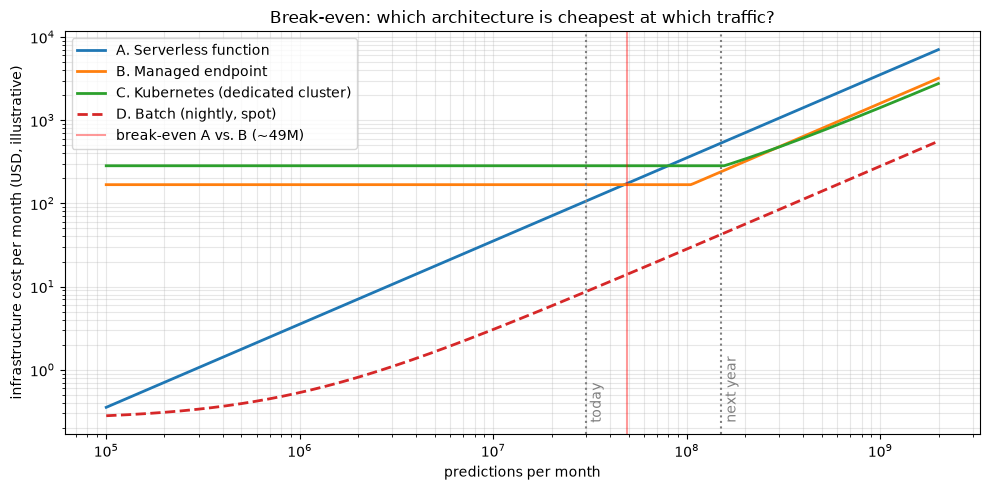

Serverless becomes more expensive than the managed endpoint above ~49M predictions/month
Managed endpoint becomes more expensive than dedicated Kubernetes above: ~292M/month


In [3]:
traffic = np.logspace(5, 9.3, 300)                                  # 100k to ~2 billion requests per month
curves = {name: np.array([f(r) for r in traffic]) for name, f in ARCHITECTURES.items()}


def crossover(a: np.ndarray, b: np.ndarray) -> float | None:
    """First traffic level where curve a becomes more expensive than curve b."""
    flips = np.where(np.diff(np.sign(a - b)) > 0)[0]
    return float(traffic[flips[0] + 1]) if len(flips) else None


be_fn_vs_endpoint = crossover(curves["A. Serverless function"], curves["B. Managed endpoint"])
be_endpoint_vs_k8s = crossover(curves["B. Managed endpoint"], curves["C. Kubernetes (dedicated cluster)"])

fig, ax = plt.subplots(figsize=(10, 5))
styles = {"A. Serverless function": "-", "B. Managed endpoint": "-", "C. Kubernetes (dedicated cluster)": "-",
          "D. Batch (nightly, spot)": "--"}
for name, values in curves.items():
    ax.loglog(traffic, values, styles[name], lw=2, label=name)
for x, label in [(W.monthly_requests, "today"), (W.growth_requests, "next year")]:
    ax.axvline(x, color="grey", ls=":"); ax.text(x * 1.05, ax.get_ylim()[0] * 1.5, label, rotation=90, color="grey")
if be_fn_vs_endpoint:
    ax.axvline(be_fn_vs_endpoint, color="red", alpha=0.4, label=f"break-even A vs. B (~{be_fn_vs_endpoint / 1e6:.0f}M)")
ax.set_xlabel("predictions per month"); ax.set_ylabel("infrastructure cost per month (USD, illustrative)")
ax.set_title("Break-even: which architecture is cheapest at which traffic?")
ax.legend(); ax.grid(alpha=0.3, which="both"); plt.tight_layout(); plt.show()

print(f"Serverless becomes more expensive than the managed endpoint above ~{be_fn_vs_endpoint / 1e6:.0f}M predictions/month")
print("Managed endpoint becomes more expensive than dedicated Kubernetes above:",
      f"~{be_endpoint_vs_k8s / 1e6:,.0f}M/month" if be_endpoint_vs_k8s else "never in this range (infra cost only)")

**Reading the chart:**
- The serverless line is straight: cost is proportional to traffic. The instance-based lines are **flat** at low traffic (the always-on minimum) and then rise. That shape is universal; only the crossing points depend on the prices.
- With these assumptions the serverless function stops being the cheaper real-time option somewhere between today's traffic and next year's (the exact crossover is printed above). **Planning only for today would choose an architecture that is wrong in a year.**
- The dedicated Kubernetes cluster carries a higher fixed minimum, and its per-request cost is only a little lower than the managed endpoint's, so on **infrastructure alone** it only catches up at very large volume (around twice next year's traffic with these prices). Its real advantages (one platform for many services, portability, fine-grained control) are not visible in a single-model cost chart, and its real cost (people) is not in it yet: Section 8 adds it.
- **Sensitivity matters more than precision.** Try the exercises: a 40% savings-plan discount on instances, or a model that needs 4 GB, moves the crossover a lot. Show management a *range*, not one number.

---
## 5. Autoscaling simulation over a daily traffic curve

The cost model above used *average* traffic. Real traffic has **peaks**, and an instance-based service must have enough capacity **at the peak**, or requests queue up and the latency SLO breaks. Autoscaling adds instances when load rises and removes them when it falls, but it reacts **with a delay** (a new instance must boot and load the 1.5 GB model).

We simulate one day, minute by minute, at **next year's** traffic (150M/month) and compare three policies on the managed endpoint:
1. **Fixed for the peak**: enough instances for the busiest minute, all day.
2. **Target tracking at 60%**: keep average CPU near 60% (the common default).
3. **Target tracking at 85%**: run hotter to save money.

Scaling rules (typical of real autoscalers): new instances are ready after **4 minutes**; instances are removed only after load has been low for **15 minutes** (cooldown, to avoid flapping); minimum 2, maximum 20.

We count two kinds of bad minutes. **Overloaded** (demand > capacity): requests pile up and the SLO is broken. **Hot** (utilisation > 90%): not yet overloaded, but queueing theory says waiting time grows like `1 / (1 - utilisation)`, so p95 latency is already climbing steeply ([Google SRE: Handling Overload](https://sre.google/sre-book/handling-overload/)).

In [4]:
def daily_traffic(avg_rps: float, rng: np.random.Generator) -> np.ndarray:
    """Requests per second for each minute of one day: night trough, lunch and evening peaks, noise, one burst."""
    t = np.arange(1440) / 60.0                                         # hour of day as a float
    shape = (0.25 + 0.9 * np.exp(-((t - 12.5) / 1.8) ** 2) + 1.3 * np.exp(-((t - 20.0) / 2.2) ** 2)
             + 0.35 * np.exp(-((t - 9.0) / 1.5) ** 2))
    rps = avg_rps * shape / shape.mean() * rng.lognormal(0, 0.08, 1440)
    rps[15 * 60:15 * 60 + 12] += 4 * avg_rps                           # 15:00 a shop re-checks its catalogue
    return rps


def simulate_autoscaling(demand: np.ndarray, cap: float, target: float | None, min_n: int = 2, max_n: int = 20,
                         warmup_min: int = 4, cooldown_min: int = 15) -> dict:
    """Minute-by-minute instance count. target=None means fixed capacity for the peak."""
    if target is None:
        n_fixed = math.ceil(demand.max() / (cap * 0.8))                # peak at 80% CPU
        instances = np.full(len(demand), n_fixed)
    else:
        instances, n, pending, low_since = [], min_n, [], 0            # pending = minutes when new instances are ready
        for minute, rps in enumerate(demand):
            n += sum(1 for ready_at in pending if ready_at == minute)  # instances that finished booting
            pending = [r for r in pending if r > minute]
            desired = int(np.clip(math.ceil(rps / (cap * target)), min_n, max_n))
            if desired > n + len(pending):                             # scale out (takes warmup_min minutes)
                pending += [minute + warmup_min] * (desired - n - len(pending))
                low_since = minute
            elif desired < n:
                if minute - low_since >= cooldown_min:                 # scale in only after a calm period
                    n, low_since = desired, minute
            else:
                low_since = minute
            instances.append(n)
        instances = np.array(instances)
    capacity = instances * cap
    utilisation = demand / capacity
    return {"instances": instances,
            "instance_hours_per_day": instances.sum() / 60,
            "monthly_cost": instances.sum() / 60 * 30 * PRICES["endpoint_instance_hour"],
            "hot_minutes_util>90%": int((utilisation > 0.9).sum()),     # queues build up, p95 latency suffers
            "overloaded_minutes": int((utilisation > 1.0).sum()),       # more work than capacity: SLO broken
            "requests_over_capacity_%": 100 * np.clip(demand - capacity, 0, None).sum() / demand.sum()}


avg_rps_next_year = W.growth_requests / (30 * 86400)
demand = daily_traffic(avg_rps_next_year, RNG)
cap = capacity_rps(2)                                                  # ~33 req/s per instance at 100% CPU
policies = {"fixed for peak": None, "target 60%": 0.60, "target 85%": 0.85}
sims = {name: simulate_autoscaling(demand, cap, target) for name, target in policies.items()}

summary = pd.DataFrame({name: {k: v for k, v in s.items() if k != "instances"} for name, s in sims.items()}).T
print(f"average {avg_rps_next_year:.0f} req/s, peak {demand.max():.0f} req/s (peak/average = {demand.max() / demand.mean():.1f}x)")
summary.round(2)

average 58 req/s, peak 273 req/s (peak/average = 4.6x)


,instance_hours_per_day,monthly_cost,hot_minutes_util>90%,overloaded_minutes,requests_over_capacity_%
fixed for peak,264.00,910.80,0.0,0.0,0.00
target 60%,95.83,330.62,4.0,4.0,0.78
target 85%,75.38,260.07,7.0,4.0,0.94


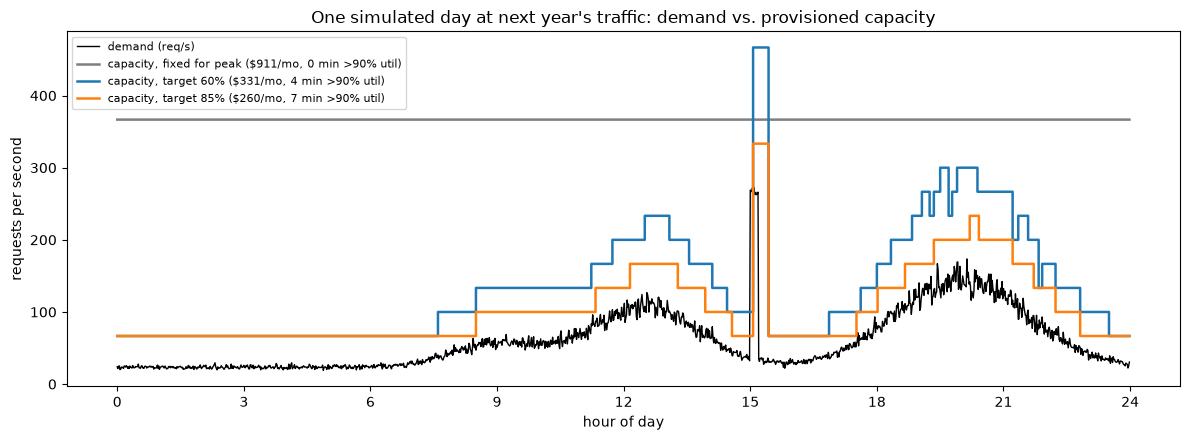

In [5]:
hours = np.arange(1440) / 60
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(hours, demand, color="black", lw=1, label="demand (req/s)")
for (name, s), color in zip(sims.items(), ["tab:grey", "tab:blue", "tab:orange"]):
    ax.step(hours, s["instances"] * cap, where="post", color=color, lw=1.8,
            label=f"capacity, {name} (${s['monthly_cost']:,.0f}/mo, {s['hot_minutes_util>90%']} min >90% util)")
ax.set_xlabel("hour of day"); ax.set_ylabel("requests per second"); ax.set_xticks(range(0, 25, 3))
ax.set_title("One simulated day at next year's traffic: demand vs. provisioned capacity")
ax.legend(fontsize=8, loc="upper left"); plt.tight_layout(); plt.show()

**What the simulation shows:**
- **Fixed for the peak** never overloads, but pays for peak capacity 24 hours a day: it costs nearly 3x the 60% policy. The peak is set by the 15:00 burst (peak/average is about 4.6x), so most of that capacity is idle almost all day.
- **Target 60%** follows the daily curve at about a third of the cost. It still has a few overloaded minutes: the 15:00 burst arrives faster than new instances can boot (4 minutes). Those are the minutes where the latency SLO breaks.
- **Target 85%** saves roughly another 20%, with the same burst overload and a few more hot minutes (7 vs. 4 here). The extra risk looks small in this simulation because our simulated traffic is smooth outside the burst; real traffic is noisier, and an 85% target leaves almost no buffer for a surprise or for an instance that fails. Whether the saving is worth that risk is a business decision; many teams settle on 60-70%.
- The lesson: autoscaling saves a large share of the cost, but **bursts beat the autoscaler**: both target policies overload during the burst. Teams handle bursts with headroom, scheduled scaling before known peaks, a queue for burst clients, or by moving bulk "re-check the whole catalogue" jobs to the **batch** path.

---
## 6. GPU vs. CPU: cost per 1,000 predictions

"Should we use GPUs?" is a cost question first. A GPU instance costs several times more per hour, but with **dynamic batching** it processes many requests at once. Illustrative throughput assumptions for our small transformer:
- **CPU**: 4-vCPU instance, ~66 predictions/s (4 / 0.060 s), ~60 ms latency.
- **GPU**: 1x A10G-class instance, ~800 predictions/s with dynamic batching, ~15 ms latency.

The catch: you buy GPUs **in whole instances**. At low traffic one GPU sits mostly idle and every prediction carries its idle cost.

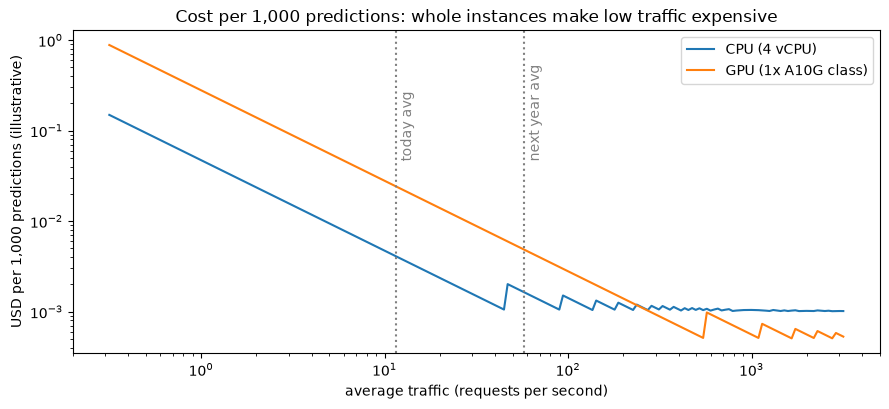

today             11.6 req/s | CPU $0.0041 | GPU $0.0241 per 1k predictions
next year         57.9 req/s | CPU $0.0016 | GPU $0.0048 per 1k predictions
10x next year    578.7 req/s | CPU $0.0011 | GPU $0.0010 per 1k predictions
GPU becomes cheaper per prediction above ~237 req/s


In [6]:
CPU_THROUGHPUT, GPU_THROUGHPUT = 4 / W.cpu_seconds_per_request, 800.0     # predictions per second per instance (illustrative)


def cost_per_1k(rps: float, throughput: float, price_hour: float, target_util: float = 0.7, min_instances: int = 1) -> float:
    instances = max(min_instances, math.ceil(rps / (throughput * target_util)))
    return instances * price_hour / (rps * 3600) * 1000


rps_grid = np.logspace(-0.5, 3.5, 200)
cpu_cost = [cost_per_1k(r, CPU_THROUGHPUT, PRICES["cpu_4vcpu_instance_hour"]) for r in rps_grid]
gpu_cost = [cost_per_1k(r, GPU_THROUGHPUT, PRICES["gpu_instance_hour"]) for r in rps_grid]
cheaper_gpu = np.array(gpu_cost) < np.array(cpu_cost)
first_gpu_win = rps_grid[np.argmax(cheaper_gpu)] if cheaper_gpu.any() else None

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.loglog(rps_grid, cpu_cost, label="CPU (4 vCPU)"); ax.loglog(rps_grid, gpu_cost, label="GPU (1x A10G class)")
for x, label in [(W.monthly_requests / (30 * 86400), "today avg"), (avg_rps_next_year, "next year avg")]:
    ax.axvline(x, color="grey", ls=":"); ax.text(x * 1.05, max(cpu_cost) / 3, label, rotation=90, color="grey")
ax.set_xlabel("average traffic (requests per second)"); ax.set_ylabel("USD per 1,000 predictions (illustrative)")
ax.set_title("Cost per 1,000 predictions: whole instances make low traffic expensive"); ax.legend()
plt.tight_layout(); plt.show()

for label, rps in [("today", W.monthly_requests / (30 * 86400)), ("next year", avg_rps_next_year), ("10x next year", 10 * avg_rps_next_year)]:
    print(f"{label:14s} {rps:7.1f} req/s | CPU ${cost_per_1k(rps, CPU_THROUGHPUT, PRICES['cpu_4vcpu_instance_hour']):.4f}"
          f" | GPU ${cost_per_1k(rps, GPU_THROUGHPUT, PRICES['gpu_instance_hour']):.4f} per 1k predictions")
print(f"GPU becomes cheaper per prediction above ~{first_gpu_win:.0f} req/s" if first_gpu_win else "GPU never cheaper here")

- At our traffic levels the CPU option is cheaper per prediction: one GPU would be mostly idle. GPUs only win per prediction at a much higher steady load (the printed crossover), when their batching throughput is actually used.
- Cost is not the only axis: if the SLO were 30 ms instead of 300 ms, the GPU's lower latency could make it necessary regardless of price. And bigger models (LLMs, large vision models) often **don't fit** a CPU budget at all.
- The saw-tooth shape is the "whole instance" effect: every time traffic needs one more instance, the cost per prediction jumps.

---
## 7. Storage, logging and egress: the "small" line items

Compute is the headline, but bills often surprise teams through the **small items that scale with traffic**. We estimate them at next year's traffic. Assumptions: every request and response is logged for monitoring/retraining and kept 90 days in standard storage, then archived for a year; application logs go to a managed log service; responses go to the internet (egress).

In [7]:
def data_costs(requests: float, w: Workload = W, p: dict = PRICES) -> pd.DataFrame:
    gb_logged_per_month = requests * (w.payload_kb + w.response_kb) / 1e6          # KB -> GB
    items = {
        "model artifacts (10 versions x 0.6 GB)": 10 * 0.6 * p["object_storage_gb_month"],
        "training data (400 GB)": 400 * p["object_storage_gb_month"],
        "prediction logs, last 90 days (standard)": 3 * gb_logged_per_month * p["object_storage_gb_month"],
        "prediction logs, 1 year archive": 12 * gb_logged_per_month * p["archive_storage_gb_month"],
        "app logs into managed log service (0.4 KB/request)": requests * 0.4 / 1e6 * p["log_ingest_gb"],
        "egress: responses to customers": requests * w.response_kb / 1e6 * p["egress_gb"],
    }
    return pd.DataFrame({"usd_per_month": items}).round(2).sort_values("usd_per_month", ascending=False)


data_table = data_costs(W.growth_requests)
print(f"total data-related cost: ${data_table['usd_per_month'].sum():,.0f}/month at 150M predictions/month")
data_table

total data-related cost: $90/month at 150M predictions/month


,usd_per_month
app logs into managed log service (0.4 KB/request),30.00
"prediction logs, last 90 days (standard)",25.88
"prediction logs, 1 year archive",18.00
training data (400 GB),9.20
egress: responses to customers,6.75
model artifacts (10 versions x 0.6 GB),0.14


Notice which line is the largest: **log ingestion**, not storage. Managed log services charge per GB *ingested*, so verbose logging of every request can cost more than storing the actual data. Typical fixes: log a sample of successful requests, ship prediction logs straight to object storage (cheap) instead of the log service, and set retention / lifecycle rules so old data moves to archive tiers automatically. Egress is small here because responses are tiny; for image or audio APIs (or cross-region replication) it can become a major item.

---
## 8. Total cost of ownership: adding the people

Infrastructure is often the *smaller* part of the cost. Running a Kubernetes cluster well (upgrades, security patches, autoscaler tuning, on-call) needs engineering time; a serverless function or managed endpoint needs much less. We add an **operations effort** estimate (fraction of one engineer's time; assumptions, discuss them with your team) at next year's traffic. We also add a variant **"C2: Kubernetes, shared platform"**: a company that *already* runs Kubernetes for other services, so the cluster fee and most of the ops effort are shared.

In [8]:
OPS_FTE = {"A. Serverless function": 0.10, "B. Managed endpoint": 0.10, "C. Kubernetes (dedicated cluster)": 0.40,
           "C2. Kubernetes (shared platform)": 0.10, "D. Batch (nightly, spot)": 0.05}


def cost_kubernetes_shared(requests: float, w: Workload = W, p: dict = PRICES) -> float:
    # no own cluster fee and no 3-node minimum: we only pay for the node-hours our pods use
    node_hours = requests / (capacity_rps(2, w) * 0.70 * 0.85 * 3600)
    return node_hours * p["vm_instance_hour"]


ALL_OPTIONS = {**ARCHITECTURES, "C2. Kubernetes (shared platform)": cost_kubernetes_shared}
data_monthly = data_costs(W.growth_requests)["usd_per_month"].sum()                  # same for every option
tco = pd.DataFrame({name: {"infra_usd": f(W.growth_requests), "data_usd": data_monthly,
                           "ops_usd": OPS_FTE[name] * ENGINEER_MONTHLY_COST} for name, f in ALL_OPTIONS.items()}).T
tco["total_usd_per_month"] = tco.sum(axis=1)
tco["real_time?"] = ["yes", "yes", "yes", "no (nightly)", "yes"]
tco.round(0).sort_values("total_usd_per_month")

,infra_usd,data_usd,ops_usd,total_usd_per_month,real_time?
"D. Batch (nightly, spot)",42.0,90.0,750.0,882.0,no (nightly)
C2. Kubernetes (shared platform),202.0,90.0,1500.0,1792.0,yes
B. Managed endpoint,240.0,90.0,1500.0,1830.0,yes
A. Serverless function,530.0,90.0,1500.0,2120.0,yes
C. Kubernetes (dedicated cluster),283.0,90.0,6000.0,6373.0,yes


Once people are included, the ranking changes character:
- The **dedicated Kubernetes cluster is by far the most expensive option overall**, almost entirely because of operations effort; its infrastructure bill is similar to the others.
- Serverless and the managed endpoint get the **same** ops estimate (serverless removes server management but adds packaging a 1.5 GB model, cold-start tuning and possibly paid *provisioned concurrency* to meet the SLO). At next year's traffic the managed endpoint is therefore the cheaper real-time option.
- On a company-wide **shared** Kubernetes platform (C2) the same workload is the cheapest real-time option of all, which is why large companies standardise on Kubernetes. But our 4-person startup doesn't have such a platform, so C2 is not really on its menu.
- Batch remains the cheapest by far, for the share of traffic that can wait.

---
## 9. A weighted decision matrix

Cost is one criterion among several. A **weighted decision matrix** makes the trade-off explicit and reviewable: score each option 1-5 per criterion, weight the criteria by what matters to *this* team, and sum. The cost score is computed from the TCO table (cheapest real-time option = 5); the other scores are judgements based on Sections 2-8, and every one of them is open to debate (that's the point: the debate happens on the scores, not on gut feeling).

We compare two **personas** with different weights: our startup, and a large enterprise with a platform team.

In [9]:
OPTIONS = ["A. Serverless function", "B. Managed endpoint", "C. Kubernetes (dedicated cluster)", "C2. Kubernetes (shared platform)"]
realtime_tco = tco.loc[OPTIONS, "total_usd_per_month"]
cost_score = 1 + 4 * (realtime_tco.max() - realtime_tco) / (realtime_tco.max() - realtime_tco.min())    # cheapest -> 5

SCORES = pd.DataFrame({                    # 1 = poor, 5 = excellent (judgement, see Sections 2-8)
    "cost at next year's traffic": cost_score.round(1),
    "latency (no cold starts)":   [2, 5, 5, 5],
    "handles bursts":             [5, 3, 4, 4],
    "low ops effort":             [5, 4, 1, 3],
    "GPU path for future models": [1, 5, 5, 5],
    "portability / lock-in":      [2, 2, 5, 5],
}, index=OPTIONS)

WEIGHTS = pd.DataFrame({                   # each persona's weights sum to 1
    "startup (4 engineers)":         [0.30, 0.20, 0.10, 0.30, 0.05, 0.05],
    "enterprise (platform team)":    [0.20, 0.20, 0.10, 0.05, 0.15, 0.30],
}, index=SCORES.columns)
assert np.allclose(WEIGHTS.sum(), 1.0)

ranking = SCORES @ WEIGHTS                 # weighted sum per option and persona
ranking.loc["C2. Kubernetes (shared platform)", "startup (4 engineers)"] = np.nan   # the startup has no shared platform
print(SCORES.to_string(), "\n")
ranking.round(2).sort_values("startup (4 engineers)", ascending=False)

                                   cost at next year's traffic  latency (no cold starts)  handles bursts  low ops effort  GPU path for future models  portability / lock-in
A. Serverless function                                     4.7                         2               5               5                           1                      2
B. Managed endpoint                                        5.0                         5               3               4                           5                      2
C. Kubernetes (dedicated cluster)                          1.0                         5               4               1                           5                      5
C2. Kubernetes (shared platform)                           5.0                         5               4               3                           5                      5 



,startup (4 engineers),enterprise (platform team)
B. Managed endpoint,4.35,3.85
A. Serverless function,3.96,2.84
C. Kubernetes (dedicated cluster),2.50,3.90
C2. Kubernetes (shared platform),NaN,4.80


For the startup persona the **managed endpoint** comes out on top: no cold starts for the 300 ms SLO, low ops effort, and cheap at next year's traffic (the shared platform is marked `NaN` because the startup doesn't have one). For the enterprise persona, which weights portability and already has a platform team, the **shared Kubernetes platform** wins, and even a dedicated cluster ranks above the managed endpoint. Same workload, different organisation, different right answer. That is why architecture decisions should be written down with their weights.

---
## 10. Keeping the bill under control: tags, budgets, anomaly alerts

Cloud bills are shared by many teams and services. Without discipline nobody knows *which* model costs what, and a forgotten GPU instance can burn money for weeks. Three practices from FinOps:

1. **Tag every resource** with who owns it and what it is for (`team`, `service`, `env`, `cost-center`, `model`). Untagged spend = spend nobody is accountable for. Enforce it in CI (policy as code) and with provider tag policies.
2. **Budgets with alerts** at, e.g., 50%, 80% and 100% of the monthly budget, on *actual* and on *forecasted* spend.
3. **Anomaly detection** on daily cost, to catch a sudden jump within a day instead of at month end.

### Tagging checklist (validated in code)

In [10]:
REQUIRED_TAGS = {"team", "service", "env", "cost-center", "owner"}
ALLOWED_ENV = {"dev", "staging", "prod"}

inventory = pd.DataFrame([      # in real life: exported from the provider's resource / cost API
    {"resource": "endpoint/reviewguard-prod", "monthly_usd": 1150, "tags": {"team": "ml", "service": "reviewguard", "env": "prod", "cost-center": "cc-42", "owner": "ana"}},
    {"resource": "bucket/reviewguard-logs",   "monthly_usd": 95,   "tags": {"team": "ml", "service": "reviewguard", "env": "prod", "cost-center": "cc-42", "owner": "ana"}},
    {"resource": "vm/gpu-experiment-7",       "monthly_usd": 734,  "tags": {"team": "ml", "owner": "ben"}},
    {"resource": "endpoint/reviewguard-stg",  "monthly_usd": 168,  "tags": {"team": "ml", "service": "reviewguard", "env": "stage", "cost-center": "cc-42", "owner": "ana"}},
    {"resource": "notebook/old-poc",          "monthly_usd": 210,  "tags": {}},
])


def tag_problems(tags: dict) -> list[str]:
    problems = [f"missing {t}" for t in sorted(REQUIRED_TAGS - tags.keys())]
    if "env" in tags and tags["env"] not in ALLOWED_ENV:
        problems.append(f"env='{tags['env']}' not in {sorted(ALLOWED_ENV)}")
    return problems


inventory["problems"] = inventory["tags"].apply(tag_problems)
inventory["compliant"] = inventory["problems"].str.len() == 0
unallocated = inventory.loc[~inventory["compliant"], "monthly_usd"].sum() / inventory["monthly_usd"].sum()
print(f"{(~inventory['compliant']).sum()} of {len(inventory)} resources break the tagging policy "
      f"-> {unallocated:.0%} of spend cannot be reliably allocated")
inventory[["resource", "monthly_usd", "compliant", "problems"]]

3 of 5 resources break the tagging policy -> 47% of spend cannot be reliably allocated


,resource,monthly_usd,compliant,problems
0,endpoint/reviewguard-prod,1150,True,[]
1,bucket/reviewguard-logs,95,True,[]
2,vm/gpu-experiment-7,734,False,"[missing cost-center, missing env, missing ser..."
3,endpoint/reviewguard-stg,168,False,"[env='stage' not in ['dev', 'prod', 'staging']]"
4,notebook/old-poc,210,False,"[missing cost-center, missing env, missing own..."


### Budget alerts and cost-anomaly detection

We simulate a month of **daily** cost for the ML account. On day 18 someone starts a large GPU training cluster for an experiment and forgets to stop it. We check two alarms every day:
- **budget forecast**: spend so far + (average daily spend of the last 7 days x remaining days) > budget,
- **anomaly**: today's cost is more than 3 standard deviations above the trailing 14-day mean (a simple version of what AWS Cost Anomaly Detection or GCP/Azure budget alerts do with smarter models).

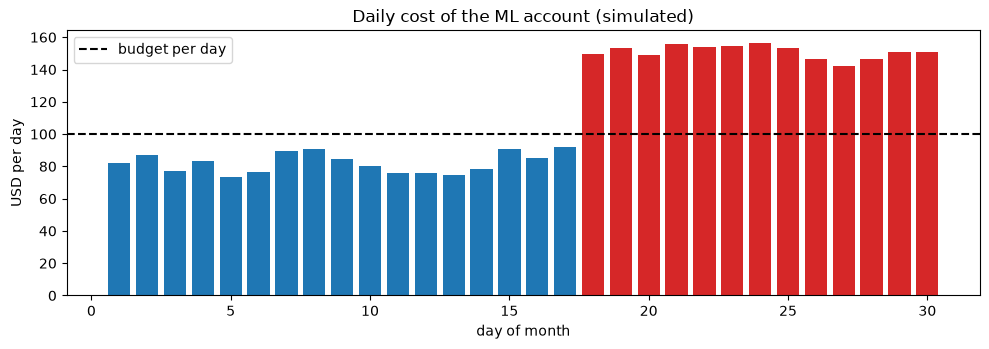

month total $3,360 vs budget $3,000


,day,alert,spent
0,18,actual >= 50%,1548
1,18,ANOMALY: daily cost spike,1548
2,19,ANOMALY: daily cost spike,1701
3,21,forecast > budget,2005
4,24,actual >= 80%,2470
5,28,actual >= 100%,3059


In [11]:
MONTHLY_BUDGET = 3_000
days = np.arange(1, 31)
daily_cost = 80 + 6 * np.sin(days / 7 * 2 * np.pi) + RNG.normal(0, 4, len(days))       # normal ~$80/day
daily_cost[days >= 18] += 24 * 3.0          # forgotten GPU cluster: ~$3/hour all day from day 18 (illustrative)

alerts = []
for i, day in enumerate(days):
    spent = daily_cost[: i + 1].sum()
    recent = daily_cost[max(0, i - 6): i + 1].mean()
    forecast = spent + recent * (len(days) - day)
    history = daily_cost[max(0, i - 14): i]
    is_anomaly = len(history) >= 7 and daily_cost[i] > history.mean() + 3 * history.std()
    for threshold in (0.5, 0.8, 1.0):                                     # actual-spend thresholds
        if spent >= threshold * MONTHLY_BUDGET and not any(a["alert"] == f"actual >= {threshold:.0%}" for a in alerts):
            alerts.append({"day": day, "alert": f"actual >= {threshold:.0%}", "spent": round(spent)})
    if forecast > MONTHLY_BUDGET and not any(a["alert"] == "forecast > budget" for a in alerts):
        alerts.append({"day": day, "alert": "forecast > budget", "spent": round(spent)})
    if is_anomaly:
        alerts.append({"day": day, "alert": "ANOMALY: daily cost spike", "spent": round(spent)})

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar(days, daily_cost, color=["tab:red" if d >= 18 else "tab:blue" for d in days])
ax.axhline(MONTHLY_BUDGET / 30, color="black", ls="--", label="budget per day")
ax.set_xlabel("day of month"); ax.set_ylabel("USD per day"); ax.set_title("Daily cost of the ML account (simulated)")
ax.legend(); plt.tight_layout(); plt.show()
print(f"month total ${daily_cost.sum():,.0f} vs budget ${MONTHLY_BUDGET:,}")
pd.DataFrame(alerts)

The anomaly alarm fires on **day 18**, the day the cluster was forgotten, and the budget forecast alarm follows shortly after, while there is still time to act. Without them, the team would discover the overspend on the invoice next month. The fix (stop the cluster) is cheap; *noticing* is the hard part.

Creating such a budget is one API call. The cell below prepares the request for the AWS Budgets API (`create_budget`); it only sends it if you set `RUN_CLOUD=1` **and** have credentials configured, otherwise it just prints the payload. GCP (Cloud Billing budgets) and Azure (Cost Management budgets) offer the same feature.

In [12]:
RUN_CLOUD = os.environ.get("RUN_CLOUD") == "1"               # default OFF: this notebook never calls a cloud API

budget_request = {
    "AccountId": "<your-12-digit-account-id>",
    "Budget": {"BudgetName": "ml-reviewguard-monthly", "BudgetType": "COST", "TimeUnit": "MONTHLY",
               "BudgetLimit": {"Amount": str(MONTHLY_BUDGET), "Unit": "USD"},
               "CostFilters": {"TagKeyValue": ["user:service$reviewguard"]}},    # only this service's tagged spend
    "NotificationsWithSubscribers": [
        {"Notification": {"NotificationType": kind, "ComparisonOperator": "GREATER_THAN",
                          "Threshold": pct, "ThresholdType": "PERCENTAGE"},
         "Subscribers": [{"SubscriptionType": "EMAIL", "Address": "ml-team@example.com"}]}
        for kind, pct in [("ACTUAL", 50), ("ACTUAL", 80), ("ACTUAL", 100), ("FORECASTED", 100)]],
}

if RUN_CLOUD:
    import boto3                                              # only imported when explicitly enabled
    boto3.client("budgets").create_budget(**budget_request)
    print("budget created")
else:
    print("RUN_CLOUD is not set to 1: not calling AWS. Request that would be sent:")
    print({k: v for k, v in budget_request.items() if k != "NotificationsWithSubscribers"})
    print("notifications:", [(n["Notification"]["NotificationType"], n["Notification"]["Threshold"])
                             for n in budget_request["NotificationsWithSubscribers"]])

RUN_CLOUD is not set to 1: not calling AWS. Request that would be sent:
{'AccountId': '<your-12-digit-account-id>', 'Budget': {'BudgetName': 'ml-reviewguard-monthly', 'BudgetType': 'COST', 'TimeUnit': 'MONTHLY', 'BudgetLimit': {'Amount': '3000', 'Unit': 'USD'}, 'CostFilters': {'TagKeyValue': ['user:service$reviewguard']}}}
notifications: [('ACTUAL', 50), ('ACTUAL', 80), ('ACTUAL', 100), ('FORECASTED', 100)]


---
## 11. Recommendation, summary, exercises and resources

### The recommendation (what you would send to management)

> **Now (30M predictions/month):** run the real-time API on a **managed ML endpoint** with 2 instances and target-tracking autoscaling at ~60%. A serverless function would be cheaper on infrastructure *today*, but (a) it loses to the managed endpoint before next year's traffic, (b) loading a 1.5 GB model on cold starts threatens the 300 ms p95 SLO, and (c) migrating later costs engineering time. Move the customer that accepts nightly results to a **batch job on spot instances**, which is far cheaper per prediction and takes burst load off the real-time path.
>
> **Revisit when:** traffic or prices move the break-even points (re-run this notebook with real invoices), we hire a platform team or the company adopts a shared Kubernetes platform (then option C2 wins), or a new model needs GPUs at high steady load.
>
> **Guardrails from day one:** required tags, a monthly budget with 50/80/100% and forecast alerts, daily anomaly detection, sampled request logging with lifecycle rules.

### Summary

| Practice | What we did | Where it is used in industry |
|---|---|---|
| Assumptions in one place | `Workload` + `PRICES` dataclass/dict | Every cost review and capacity plan |
| Cost model per architecture | functions `requests -> USD/month` | Architecture decision records, FinOps |
| Break-even analysis | log-log chart, crossover points | "Build vs. buy", "serverless vs. instances" decisions |
| Autoscaling simulation | minute-level demand vs. capacity, 3 policies | Capacity planning, SLO risk assessment |
| GPU vs. CPU per 1k predictions | whole-instance effect vs. traffic | Inference hardware choices |
| Small line items | logs, storage tiers, egress | Bill surprises, lifecycle policies |
| TCO with people | ops effort in FTE | Why small teams pick managed services |
| Weighted decision matrix | scores x weights per persona | Design reviews, ADRs |
| Tags, budgets, anomalies | validator, alerts, anomaly rule, Budgets API payload | FinOps practice (FinOps Foundation) |

### Practice exercises
1. Apply a 40% savings-plan discount to `endpoint_instance_hour` and `vm_instance_hour` with `PRICES = {**PRICES, ...}`. How do the break-even points move?
2. The model team ships a model needing 4 GB RAM and 150 ms per request. Update `Workload` (use `dataclasses.replace`) and re-run. Which recommendation changes?
3. Add **scheduled scaling** to `simulate_autoscaling` (pre-scale to 6 instances from 11:30 and 18:30). Does it remove the overloaded minutes? What does it cost?
4. Add a fifth architecture, *serverless containers* (pay per vCPU-second and GiB-second while handling requests, optional minimum instances), and place it in the break-even chart.
5. Change the anomaly rule to use the median and MAD (median absolute deviation) instead of mean and standard deviation. Why is that more robust?

### Resources (check current prices here)
- AWS: [Lambda pricing](https://aws.amazon.com/lambda/pricing/), [SageMaker AI pricing](https://aws.amazon.com/sagemaker-ai/pricing/), [EKS pricing](https://aws.amazon.com/eks/pricing/), [AWS Pricing Calculator](https://calculator.aws/), [AWS Budgets](https://docs.aws.amazon.com/cost-management/latest/userguide/budgets-managing-costs.html), [Well-Architected Machine Learning Lens](https://docs.aws.amazon.com/wellarchitected/latest/machine-learning-lens/machine-learning-lens.html)
- Google Cloud: [Cloud Run pricing](https://cloud.google.com/run/pricing), [Vertex AI pricing](https://cloud.google.com/vertex-ai/pricing), [Google Cloud Pricing Calculator](https://cloud.google.com/products/calculator), [Architecture Center: AI and ML](https://cloud.google.com/architecture/ai-ml)
- Azure: [Azure Machine Learning pricing](https://azure.microsoft.com/en-us/pricing/details/machine-learning/), [Azure Pricing Calculator](https://azure.microsoft.com/en-us/pricing/calculator/)
- [FinOps Foundation: FinOps Framework](https://www.finops.org/framework/)
- [Google SRE book: Handling Overload](https://sre.google/sre-book/handling-overload/) (why running hot is risky)

### Related notebooks in this repo
- `01_aws_for_ai.ipynb`, `02_gcp_for_ai.ipynb`, `03_azure_for_ai.ipynb`, `04_cloud_cost_optimization.ipynb`
- `../16_Deployment/03_serverless_deployment.ipynb` (Lambda / SageMaker / Cloud Run code), `../16_Deployment/05_industry_safe_model_rollout_strategies.ipynb`
- `../17_Docker/04_industry_containerizing_an_ml_service.ipynb`, `../17_Docker/kubernetes/01_kubernetes.ipynb`
- `../12_FastAPI/04_industry_production_ml_api.ipynb` (where the "60 ms per request" kind of number comes from)